# Kdy se Monte Carlo vyplatí

*Nad rámec cvičení — kapitoly 1.2, 5.6 a 2.4 skripta.*

---

Zbytek kurzu ukazuje, **jak** Monte Carlo dělat. Tenhle sešit se ptá na dvě otázky, které jsou před tím: **kdy** ho použít, a **jak moc** výsledku věřit.

- **Součet řady** jako střední hodnota — Monte Carlo umí víc než integrály
- **Monte Carlo vs. klasické kvadratury**: od které dimenze se vyplatí? (Odpověď je konkrétní číslo a dá se naměřit.)
- **Závislé realizace**: když vzorky nejsou nezávislé, obvyklá chybová úsečka lže — a jak moc

In [1]:
import itertools
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # opakovatelné výsledky


def estimate(sampler, n):
    """Průměr n volání generátoru a jeho směrodatná chyba sigma/sqrt(n)."""
    s = s2 = 0.0
    for _ in range(n):
        x = sampler()
        s += x
        s2 += x * x
    mean = s / n
    var = max(s2 / n - mean * mean, 0.0)
    return mean, math.sqrt(var / n)

## 1. Součet řady metodou Monte Carlo

Monte Carlo se obvykle představuje na integrálech, ale princip je obecnější: **cokoliv, co se dá napsat jako střední hodnota, se dá odhadnout průměrem.** Součet řady mezi to patří.

Chceme $S = \sum_{k=1}^{\infty} a_k$. Zvolíme libovolné rozdělení na indexech, $P(K = k) = p_k > 0$, a položíme

$$\xi = \frac{a_K}{p_K} \qquad\Longrightarrow\qquad E\,\xi = \sum_{k=1}^{\infty} p_k \frac{a_k}{p_k} = S .$$

Je to táž myšlenka jako vážení podle důležitosti ze cvičení 7, jen na diskrétní množině.

**Příklad.** $a_k = 1/k^2$, tedy $S = \pi^2/6$. Jako $p_k$ zvolíme

$$p_k = \frac{1}{k(k+1)} = \frac1k - \frac1{k+1},$$

což dává dohromady 1 a losuje se jedním číslem: $K = \lfloor 1/\gamma \rfloor$. Odhadovač pak vyjde pozoruhodně krotký:

$$\xi = \frac{a_K}{p_K} = \frac{1}{K^2}\cdot K(K+1) = 1 + \frac1K \in (1, 2].$$

Je **omezený**, takže má konečný rozptyl — a to je u nekonečných řad to podstatné.

In [2]:
def clen_rady():
    """ξ = a_K / p_K pro a_k = 1/k², p_k = 1/(k(k+1)); K = floor(1/γ)."""
    K_ = int(1.0 / random.random())
    return 1.0 + 1.0 / K_


n = 200_000
m, se = estimate(clen_rady, n)
presne = math.pi**2 / 6
print(f"MC odhad  S = {m:.6f} +- {se:.6f}")
print(f"přesně    S = {presne:.6f}   (π²/6)")
print(f"odchylka: {abs(m - presne) / se:.2f} směrodatné chyby")

# srovnání: kolik členů musíme sečíst přímo pro stejnou přesnost?
# zbytek po K členech je zhruba 1/K, takže pro chybu se potřebujeme K ≈ 1/se
castecny, k = 0.0, 0
while abs(presne - castecny) > se:
    k += 1
    castecny += 1.0 / k**2
print(f"\npřímé sčítání potřebuje {k} členů, aby bylo stejně blízko")
print(f"Monte Carlo spotřebovalo {n} náhodných čísel — tady přímé sčítání jasně vyhrává.")

MC odhad  S = 1.645337 +- 0.000840
přesně    S = 1.644934   (π²/6)
odchylka: 0.48 směrodatné chyby

přímé sčítání potřebuje 1190 členů, aby bylo stejně blízko
Monte Carlo spotřebovalo 200000 náhodných čísel — tady přímé sčítání jasně vyhrává.


Poslední řádek je důležitý a nesmí se zamlčet: **pro tuhle řadu je Monte Carlo horší volba.** Přímé sčítání konverguje rychleji a je deterministické.

Kdy tedy metoda dává smysl? Když je sčítání přes index drahé nebo nemožné:

- členy nejsou dané vzorcem, ale samy se musí simulovat,
- řada je mnohorozměrná (sčítá se přes mřížku indexů) — pak platí totéž, co uvidíme u integrálů,
- stačí nám hrubý odhad a člen $a_k$ je drahý na vyhodnocení.

Totéž ostatně platí o integrálech, a tam se to dá změřit přesně.

## 2. Monte Carlo vs. klasické kvadratury

Lichoběžníkové pravidlo s $m$ body na osu má v jedné dimenzi chybu $O(m^{-2})$. V $d$ dimenzích potřebuje mřížku $N = m^d$ bodů, takže $m = N^{1/d}$ a

$$\text{chyba} \sim m^{-2} = N^{-2/d}.$$

Monte Carlo má chybu $N^{-1/2}$ **bez ohledu na dimenzi**. Porovnáním exponentů:

$$\frac{2}{d} = \frac12 \qquad\Longleftrightarrow\qquad d = 4 .$$

Pod čtyřmi rozměry vyhrává mřížka, nad čtyřmi Monte Carlo. Pro Simpsonovo pravidlo (chyba $m^{-4}$) vyjde zlom u $d = 8$.

To není jen formální úvaha — dá se změřit. Integrujeme $\int_{[0,1]^d}\prod_i \cos x_i\,dx = \sin(1)^d$, kde přesnou hodnotu známe v každé dimenzi.

In [3]:
def f_soucin(xs):
    p = 1.0
    for x in xs:
        p *= math.cos(x)
    return p


def presne_soucin(d):
    return math.sin(1.0) ** d


def lichobeznik(d, m):
    """Lichoběžníkové pravidlo na mřížce m^d bodů."""
    h = 1.0 / (m - 1)
    tot = 0.0
    for idx in itertools.product(range(m), repeat=d):
        w = 1.0
        for i in idx:
            if i in (0, m - 1):
                w *= 0.5
        tot += w * f_soucin([i * h for i in idx])
    return tot * h**d


def mc_integral(d, n):
    s = sum(f_soucin([random.random() for _ in range(d)]) for _ in range(n))
    return s / n


print(f"{'d':>2s} {'N':>9s} {'lichoběžník':>14s} {'Monte Carlo':>14s}   vítěz")
dims, chyby_lich, chyby_mc = [], [], []
for d in (1, 2, 3, 4, 5, 6):
    m = max(3, round(10_000 ** (1.0 / d)))
    N = m**d
    e_lich = abs(lichobeznik(d, m) - presne_soucin(d))
    e_mc = sum(abs(mc_integral(d, N) - presne_soucin(d)) for _ in range(5)) / 5
    dims.append(d); chyby_lich.append(e_lich); chyby_mc.append(e_mc)
    print(f"{d:>2d} {N:>9,d} {e_lich:>14.2e} {e_mc:>14.2e}   {'lichoběžník' if e_lich < e_mc else 'Monte Carlo'}".replace(",", " "))

 d         N    lichoběžník    Monte Carlo   vítěz
 1    10 000       7.01e-10       5.65e-04   lichoběžník
 2    10 000       1.20e-05       1.26e-03   lichoběžník
 3    10 648       3.38e-04       1.57e-03   lichoběžník
 4    10 000       2.06e-03       9.24e-04   Monte Carlo
 5     7 776       6.99e-03       1.16e-03   Monte Carlo
 6    15 625       1.10e-02       1.21e-03   Monte Carlo


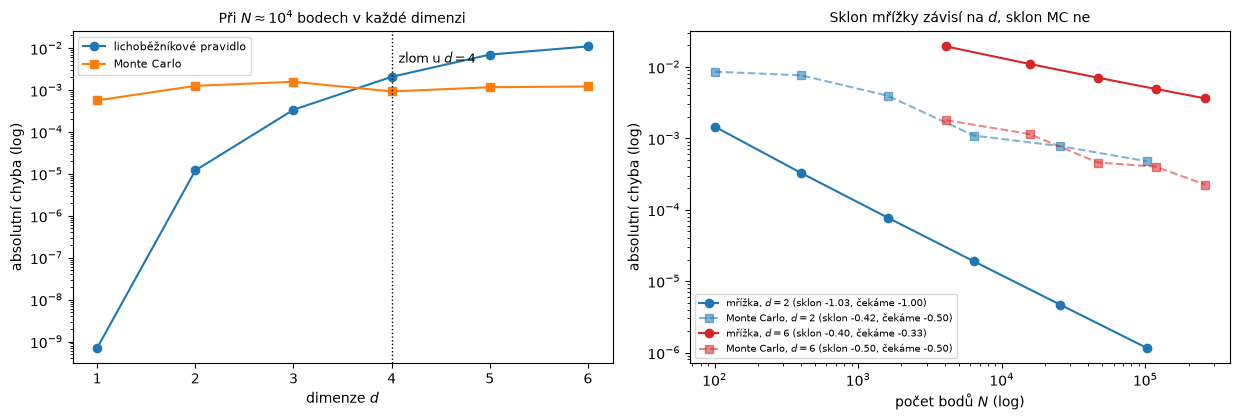

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
ax.semilogy(dims, chyby_lich, "o-", label="lichoběžníkové pravidlo")
ax.semilogy(dims, chyby_mc, "s-", label="Monte Carlo")
ax.axvline(4, color="k", ls=":", lw=1)
ax.text(4.07, max(chyby_lich) * 0.4, "zlom u $d = 4$", fontsize=9)
ax.set_xlabel("dimenze $d$")
ax.set_ylabel("absolutní chyba (log)")
ax.set_title("Při $N \\approx 10^4$ bodech v každé dimenzi", fontsize=10)
ax.legend(fontsize=8)

# jak chyba klesá s N pro pevné d (sklon v log-log měřítku)
ax = axes[1]
OPAK = 12
for d, ms, barva in ((2, (10, 20, 40, 80, 160, 320), "tab:blue"),
                     (6, (4, 5, 6, 7, 8), "tab:red")):
    Ns = [m**d for m in ms]
    e_l = [abs(lichobeznik(d, m) - presne_soucin(d)) for m in ms]
    e_m = [sum(abs(mc_integral(d, N) - presne_soucin(d)) for _ in range(OPAK)) / OPAK for N in Ns]
    sklon_l = (math.log(e_l[-1]) - math.log(e_l[0])) / (math.log(Ns[-1]) - math.log(Ns[0]))
    sklon_m = (math.log(e_m[-1]) - math.log(e_m[0])) / (math.log(Ns[-1]) - math.log(Ns[0]))
    ax.loglog(Ns, e_l, "o-", color=barva, label=f"mřížka, $d={d}$ (sklon {sklon_l:.2f}, čekáme {-2/d:.2f})")
    ax.loglog(Ns, e_m, "s--", color=barva, alpha=0.55,
              label=f"Monte Carlo, $d={d}$ (sklon {sklon_m:.2f}, čekáme -0.50)")
ax.set_xlabel("počet bodů $N$ (log)")
ax.set_ylabel("absolutní chyba (log)")
ax.set_title("Sklon mřížky závisí na $d$, sklon MC ne", fontsize=10)
ax.legend(fontsize=7, loc="lower left")

plt.tight_layout()
plt.show()

Levý graf je ta předpověď změřená: do tří rozměrů vyhrává mřížka, od čtyř Monte Carlo, a zlom sedí přesně tam, kde ho počítání exponentů čekalo.

Pravý graf ukazuje **proč**. Sklon křivky lichoběžníkového pravidla v log-log měřítku je $-2/d$, takže se s rostoucí dimenzí láme do vodorovna. Sklon Monte Carla je $-1/2$ pořád stejný — dimenze ho nezajímá.

Dvě poznámky, aby obrázek nesváděl k příliš jednoduchému závěru:

- **Hladkost se počítá.** Kvadratury těží z hladkosti integrandu. Pro nehladkou funkci (zlom, singularita, charakteristická funkce složité oblasti) spadne jejich řád i v nízké dimenzi, a Monte Carlo vyhrává dřív.
- **„Dimenze" nemusí být geometrická.** Simulace pojišťovny ze cvičení 2 je vlastně integrál přes $N = 365$ náhodných čísel. Mřížkově by se počítat nedal, ani náhodou.

## 3. Závislé realizace

Všude v kurzu stojí chybová úsečka na vzorci

$$D\,\bar\xi_N = \frac{\sigma^2}{N},$$

který platí **jen pro nezávislé** vzorky. Když jsou vzorky závislé — a to nastane vždy, když se stav generuje z předchozího (markovské řetězce, MCMC, simulace fronty v čase) — je skutečný rozptyl jiný:

$$D\,\bar\xi_N = \frac{\sigma^2}{N}\Big(1 + 2\sum_{\ell=1}^{\infty}\rho_\ell\Big) \;=\; \frac{\sigma^2}{N}\cdot\tau,$$

kde $\rho_\ell$ je autokorelace na odstup $\ell$ a $\tau$ je **integrovaný autokorelační čas**. Pro kladně korelované vzorky je $\tau > 1$, tedy skutečná chyba je **větší** než ta naivní.

Vyzkoušíme to na posloupnosti AR(1), $x_t = \varphi x_{t-1} + \varepsilon_t$, kde $\tau = \frac{1+\varphi}{1-\varphi}$ se dá spočítat přesně.

In [5]:
def ar1(N, phi, sigma=1.0):
    """Posloupnost x_t = phi*x_{t-1} + šum; zahozením začátku se zbavíme přechodového jevu."""
    x = random.gauss(0, sigma / math.sqrt(1 - phi * phi))
    out = []
    for _ in range(N):
        x = phi * x + random.gauss(0, sigma)
        out.append(x)
    return out


def naivni_chyba(xs):
    n = len(xs)
    m = sum(xs) / n
    var = sum((v - m) ** 2 for v in xs) / (n - 1)
    return math.sqrt(var / n)


def chyba_po_blocich(xs, B=500):
    """Metoda průměrů po blocích: bloky délky B jsou skoro nezávislé."""
    nb = len(xs) // B
    bloky = [sum(xs[i * B:(i + 1) * B]) / B for i in range(nb)]
    m = sum(bloky) / nb
    var = sum((v - m) ** 2 for v in bloky) / (nb - 1)
    return math.sqrt(var / nb)


N = 100_000
print(f"{'φ':>6s} {'naivní chyba':>14s} {'po blocích':>12s} {'poměr':>8s} {'√τ (teorie)':>13s}")
phis, pomery, teorie = [], [], []
for phi in (0.0, 0.3, 0.6, 0.8, 0.9, 0.95):
    xs = ar1(N, phi)
    a, b = naivni_chyba(xs), chyba_po_blocich(xs)
    t = math.sqrt((1 + phi) / (1 - phi))
    phis.append(phi); pomery.append(b / a); teorie.append(t)
    print(f"{phi:>6.2f} {a:>14.5f} {b:>12.5f} {b / a:>8.2f} {t:>13.2f}")

     φ   naivní chyba   po blocích    poměr   √τ (teorie)
  0.00        0.00316      0.00342     1.08          1.00
  0.30        0.00331      0.00449     1.35          1.36
  0.60        0.00396      0.00797     2.01          2.00
  0.80        0.00525      0.01666     3.18          3.00
  0.90        0.00721      0.03359     4.66          4.36
  0.95        0.01017      0.06021     5.92          6.24


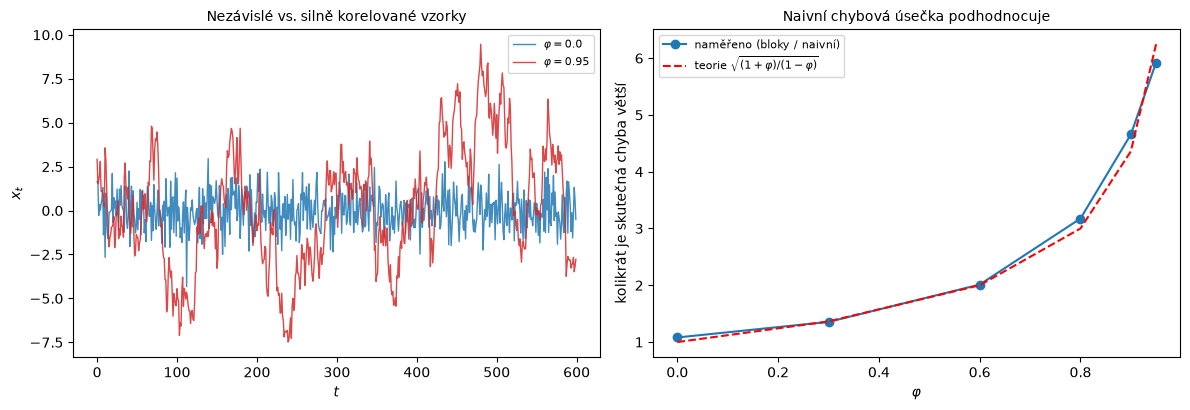

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
for phi, barva in ((0.0, "tab:blue"), (0.95, "tab:red")):
    ax.plot(ar1(600, phi), lw=1, color=barva, alpha=0.85, label=f"$\\varphi = {phi}$")
ax.set_xlabel("$t$")
ax.set_ylabel("$x_t$")
ax.set_title("Nezávislé vs. silně korelované vzorky", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(phis, pomery, "o-", label="naměřeno (bloky / naivní)")
ax.plot(phis, teorie, "r--", label=r"teorie $\sqrt{(1+\varphi)/(1-\varphi)}$")
ax.set_xlabel(r"$\varphi$")
ax.set_ylabel("kolikrát je skutečná chyba větší")
ax.set_title("Naivní chybová úsečka podhodnocuje", fontsize=10)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

Levý graf ukazuje, co znamená závislost: při $\varphi = 0.95$ se posloupnost „plazí" — sousední hodnoty jsou skoro stejné, takže sto vzorků nese míň informace než sto nezávislých.

Pravý graf to vyčísluje. Při $\varphi = 0.95$ je skutečná chyba zhruba **šestkrát** větší, než naivní vzorec tvrdí. Kdo mu uvěří, ohlásí šestkrát užší interval spolehlivosti, než na jaký má nárok — a bude si jistý něčím, co není pravda.

Jak se tomu bránit:

1. **Průměry po blocích.** Rozděl běh na bloky delší než korelační čas a zacházej s jejich průměry jako s nezávislými vzorky. Jednoduché a spolehlivé.
2. **Prořídit** (vzít každý $k$-tý vzorek). Funguje, ale zbytečně zahazuje informaci; bloky jsou lepší.
3. **Odhadnout $\tau$** přímo ze součtu autokorelací a naivní chybu jím vynásobit.

## Shrnutí

| Otázka | Odpověď |
|---|---|
| Umí MC jen integrály? | Ne — cokoliv ve tvaru střední hodnoty, včetně součtu řady: $\xi = a_K/p_K$ |
| Vyplatí se MC v 1D? | Ne. Kvadratura je tam o mnoho řádů lepší. |
| Od kdy se vyplatí? | Lichoběžník $N^{-2/d}$ vs MC $N^{-1/2}$ ⟹ zlom u **$d = 4$** (Simpson u $d = 8$) |
| A pro nehladké funkce? | Dřív — kvadratury ztrácejí řád, MC ne |
| Platí $\sigma^2/N$ vždy? | **Ne**, jen pro nezávislé vzorky. Jinak $\tau\sigma^2/N$ |
| Co s tím? | Průměry po blocích, prořídit, nebo odhadnout $\tau$ |

Hlavní myšlenka: silná stránka Monte Carla není přesnost, ale **lhostejnost k dimenzi**. V jedné dimenzi prohraje s čímkoliv; ve stovce rozměrů nemá konkurenci.

### Zkuste si

1. Odhadněte $\sum 1/k^3$ stejnou metodou. Jaké $p_k$ zvolíte, aby byl odhadovač omezený?
2. Zkuste $p_k$ geometrické, $p_k = 2^{-k}$, pro $\sum 1/k^2$. Spočítejte rozptyl odhadovače a vysvětlete, proč je mnohem horší.
3. Nahraďte lichoběžníkové pravidlo Simpsonovým a ověřte, že se zlom posune k $d = 8$.
4. Integrujte nehladkou funkci — třeba $\mathbf 1[\sum x_i < d/2]$ — a zjistěte, kde je zlom teď.
5. Ve srovnání chyb změřte sklon přímek v log-log měřítku a porovnejte s $-2/d$ a $-1/2$.
6. Pro AR(1) s $\varphi = 0.9$ zjistěte, jak dlouhé bloky jsou potřeba, aby odhad chyby přestal růst s délkou bloku.